In [1]:
#install dependencies b/c enviornment/kernel has not yet been set up
#uncomment to run
#%pip install pandas numpy rdkit matplotlib seaborn scikit=learn xgboost

In [2]:
# Import packages
#Basic
import os
import pandas as pd
import numpy as np

#Chem
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors, PandasTools, rdFingerprintGenerator
from rdkit.DataStructs import TanimotoSimilarity

#Visualization
import matplotlib.pyplot as plt
import seaborn as sns
# Set up a consistent plotting style
plt.style.use("default")
sns.set_palette("husl")

# Jupyter command to make more than one output show up
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [3]:
# Set Random Seed for Reproducibility
RANDOM_SEED = 1147 
np.random.seed(RANDOM_SEED)

In [1]:
# Load in full dataset locally
DATA_DIR = "data/raw"
DATA_FILE = os.path.join(DATA_DIR, "apistox_full_raw.csv")
df = pd.read_csv(DATA_FILE)
display(df.head())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

NameError: name 'os' is not defined

In [5]:
# Load in train/test datasets for all three splits
# create DATA_FILE for other 6 datasets
DATA_FILE1 = os.path.join(DATA_DIR, "random_train_raw.csv")
DATA_FILE2 = os.path.join(DATA_DIR, "random_test_raw.csv")
DATA_FILE3 = os.path.join(DATA_DIR, "maxmin_train_raw.csv")
DATA_FILE4 = os.path.join(DATA_DIR, "maxmin_test_raw.csv")
DATA_FILE5 = os.path.join(DATA_DIR, "time_train_raw.csv")
DATA_FILE6 = os.path.join(DATA_DIR, "time_test_raw.csv")

### Import All Pre-Made ApisTox Train-Test Splits ###
random_train = pd.read_csv(DATA_FILE1)
random_test = pd.read_csv(DATA_FILE2)
time_train = pd.read_csv(DATA_FILE3)
time_test = pd.read_csv(DATA_FILE4)
maxmin_train = pd.read_csv(DATA_FILE5)
maxmin_test = pd.read_csv(DATA_FILE6)

print(f"Train Set Size Verification -- Random: {random_train.shape}, Time: {time_train.shape}, MaxMin: {maxmin_train.shape} ")
print(f"Test Set Size Verification -- Random: {random_test.shape}, Time: {time_test.shape}, MaxMin: {maxmin_test.shape} ")

Train Set Size Verification -- Random: (828, 13), Time: (828, 13), MaxMin: (828, 13) 
Test Set Size Verification -- Random: (207, 13), Time: (207, 13), MaxMin: (207, 13) 


In [6]:
### Create Fingerprints ###
#add 'mol' molecule type as a new column to the dataframe
PandasTools.AddMoleculeColumnToFrame(df, smilesCol='SMILES', molCol='molecule')

#create a morgan fingerprints data frame
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

# Generate fingerprints for all molecules
fingerprints = []
for mol in df['molecule']:
    fp = morgan_gen.GetFingerprint(mol)
    fingerprints.append(fp.ToList())

# Convert to DataFrame with indexed column names
fp_columns = [f'Morgan_bit_{i}' for i in range(2048)]
fingerprint_df = pd.DataFrame(fingerprints, columns=fp_columns, index=df.index)
df_fp = pd.concat([df, fingerprint_df], axis=1)

print(f"Dataframe of fingerprints shape: {fingerprint_df.shape}")

#create two df for 'nontox' and 'tox' levels
nontox_df = df[df['ppdb_level'] == 0]
toxic_df = df[df['ppdb_level'] == 2]

print(len(nontox_df), len(toxic_df))
df_fp.shape

Dataframe of fingerprints shape: (1035, 2048)
177 171


(1035, 2062)

In [7]:
### Computing Tanimoto Similarity ###
def compare_fp_parameters(mols, molecule_names, radius, fp_size, column):
    generator = rdFingerprintGenerator.GetMorganGenerator(
        radius=radius,
        fpSize=fp_size
    )
    fingerprints = [generator.GetFingerprint(mol) for mol in column]

    matrix = []
    for fp_a in fingerprints:
        row = [
            TanimotoSimilarity(fp_a, fp_b)
            for fp_b in fingerprints
        ]
        matrix.append(row)

    return pd.DataFrame(matrix)
mols_nontox = nontox_df['molecule'].tolist() #.iloc[:177].tolist()
names_nontox = nontox_df['name'].tolist() #[:177].astype(str).tolist()

print(len(mols_nontox), len(names_nontox))

177 177


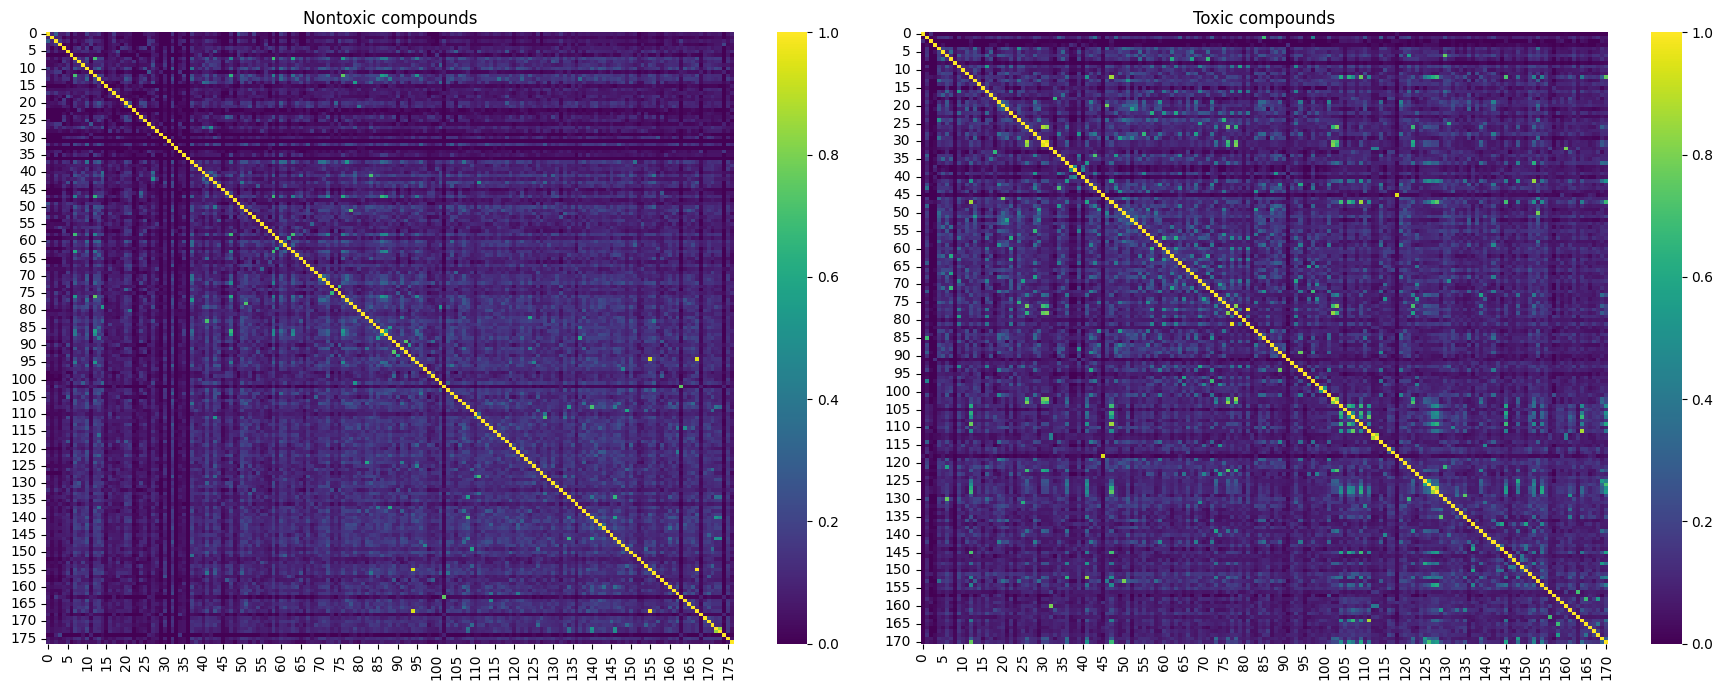

In [8]:
### Plot Similarities in Nontoxic and Toxic ###
similarity_nontox = compare_fp_parameters(
    mols_nontox, names_nontox, radius=2, fp_size=1024, column = nontox_df['molecule']) 
similarity_tox = compare_fp_parameters(
    mols_nontox, names_nontox, radius=2, fp_size=1024, column = toxic_df['molecule'])
fig, axes = plt.subplots(1, 2, figsize=(18, 7)) # plot matrices side-by-side

sns.heatmap(similarity_nontox, ax=axes[0], cmap="viridis", vmin=0, vmax=1)
axes[0].set_title("Nontoxic compounds")

sns.heatmap(similarity_tox, ax=axes[1], cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("Toxic compounds")

plt.tight_layout()
plt.show();

In [9]:
#%pip install numba umap-learn
import umap

/Users/ellasatterthwaite/Desktop/che1147/che1147-bees/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [10]:
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors, PandasTools, rdFingerprintGenerator
from rdkit.DataStructs import TanimotoSimilarity
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

In [11]:
def add_fp(dataframe):
    if dataframe.shape[1] < 1000: #use to not accidentally add columns twice

        PandasTools.AddMoleculeColumnToFrame(dataframe, smilesCol='SMILES', molCol='molecule')

        morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    
        # Generate fingerprints for all molecules
        fingerprints = []
        for mol in dataframe['molecule']:
            fp = morgan_gen.GetFingerprint(mol)
            fingerprints.append(fp.ToList())

        # Convert to DataFrame with indexed column names
        fp_columns = [f'Morgan_bit_{i}' for i in range(2048)]
        fingerprint_df = pd.DataFrame(fingerprints, columns=fp_columns, index=dataframe.index)
        
        dataframe = pd.concat([dataframe, fingerprint_df], axis=1)
        
        return dataframe
    else:
        return dataframe

In [12]:
df.head()
random_train.head()

,name,CID,CAS,SMILES,source,year,toxicity_type,herbicide,fungicide,insecticide,other_agrochemical,label,ppdb_level,molecule
0,Ethanedioic acid,971,144-62-7,O=C(O)C(=O)O,ECOTOX,1832,Contact,0,0,0,0,0,0,<rdkit.Chem.rdchem.Mol object at 0x117837ca0>
1,Para-cymene,7463,99-87-6,Cc1ccc(C(C)C)cc1,BPDB,1833,Other,0,0,0,1,0,1,<rdkit.Chem.rdchem.Mol object at 0x117837e60>
2,Kieselguhr,24261,61790-53-2,O=[Si]=O,ECOTOX,1833,Contact,0,0,0,0,0,0,<rdkit.Chem.rdchem.Mol object at 0x117837f40>
3,Benzoic acid,243,65-85-0,O=C(O)c1ccccc1,ECOTOX,1833,Contact,1,1,1,0,0,1,<rdkit.Chem.rdchem.Mol object at 0x11784c040>
4,Tetradifon (Ref: ENT 23737),8305,116-29-0,O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,PPDB,1836,Oral,0,0,0,1,1,1,<rdkit.Chem.rdchem.Mol object at 0x11784c0b0>


,name,CID,CAS,SMILES,source,year,toxicity_type,herbicide,fungicide,insecticide,other_agrochemical,label,ppdb_level
0,Mepiquat chloride (Ref: BAS 083W),62781,24307-26-4,C[N+]1(C)CCCCC1.[Cl-],PPDB,1980,Contact,0,0,0,1,0,1
1,"N-(2,6-Dichlorophenyl)-5-ethoxy-7-fluoro-[1,2,...",3081304,145701-21-9,CCOc1nc(F)cc2nc(S(=O)(=O)Nc3c(Cl)cccc3Cl)nn12,ECOTOX,2000,Contact,1,0,0,0,0,1
2,(Acetato-kappaO)phenylmercury,16682730,62-38-4,CC(=O)O[Hg]c1ccccc1,ECOTOX,1891,Oral,0,0,0,0,1,1
3,"As,As-Dimethylarsinic acid",2513,75-60-5,C[As](C)(=O)O,ECOTOX,1901,Contact,1,0,0,0,0,0
4,Tritosulfuron,11657899,142469-14-5,COc1nc(NC(=O)NS(=O)(=O)c2ccccc2C(F)(F)F)nc(C(F...,PPDB,2007,Contact,1,0,0,0,0,0


In [13]:
# add a boolean vector to describe if a point in the main dataframe is found in the training split for the random, maxmin and time splits.
df = add_fp(df)
# add a 1 to column is the row is present in another dataframe, add a 0 if not.
df['in_random_train'] = df['CAS'].isin(random_train['CAS']).astype(int)
#df[in_random] = if col in col 
df['in_max_train'] = df['CAS'].isin(maxmin_train['CAS']).astype(int)
#df[in_time] = 
df['in_time_train'] = df['CAS'].isin(time_train['CAS']).astype(int)

In [14]:
# print to verify the above
RANDOM_TARGET = "in_random_train"
MAX_TARGET = "in_max_train"
TIME_TARGET = "in_time_train"

In [15]:
#define targets for model
TARGET = "ppdb_level"
FEATURES = [col for col in df.columns if col.startswith("Morgan_bit_")]

In [22]:
#fit a UMAP projection model onto the features of the full dataframe
mapper = umap.UMAP(n_neighbors=15, min_dist=.6, n_components=2).fit(df[FEATURES])

/var/folders/z5/s_lphsr53bzfx0zyptx_j77c0000gn/T/ipykernel_93848/576961556.py:2: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  mapper = umap.UMAP(n_neighbors=15, min_dist=.6, n_components=2).fit(df[FEATURES])


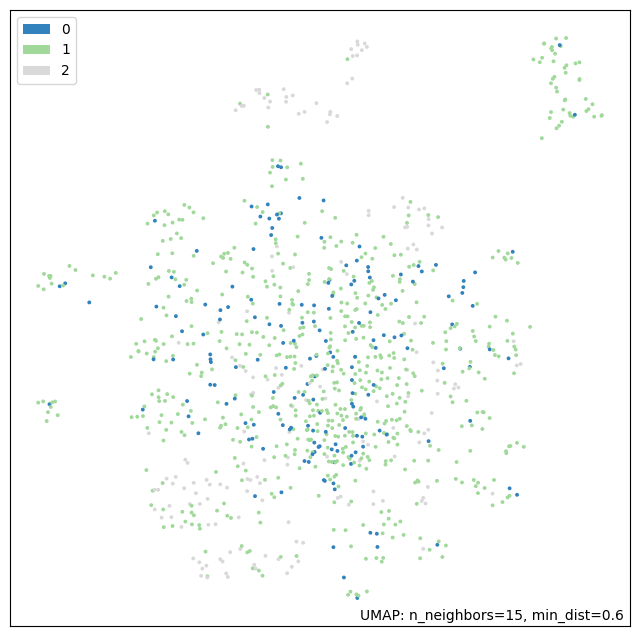

In [23]:
#import umap plotter and plot points labeled with toxicity class.
import umap.plot
#umap.plot.points(mapper);
umap.plot.points(mapper, labels=df[TARGET], theme='green');

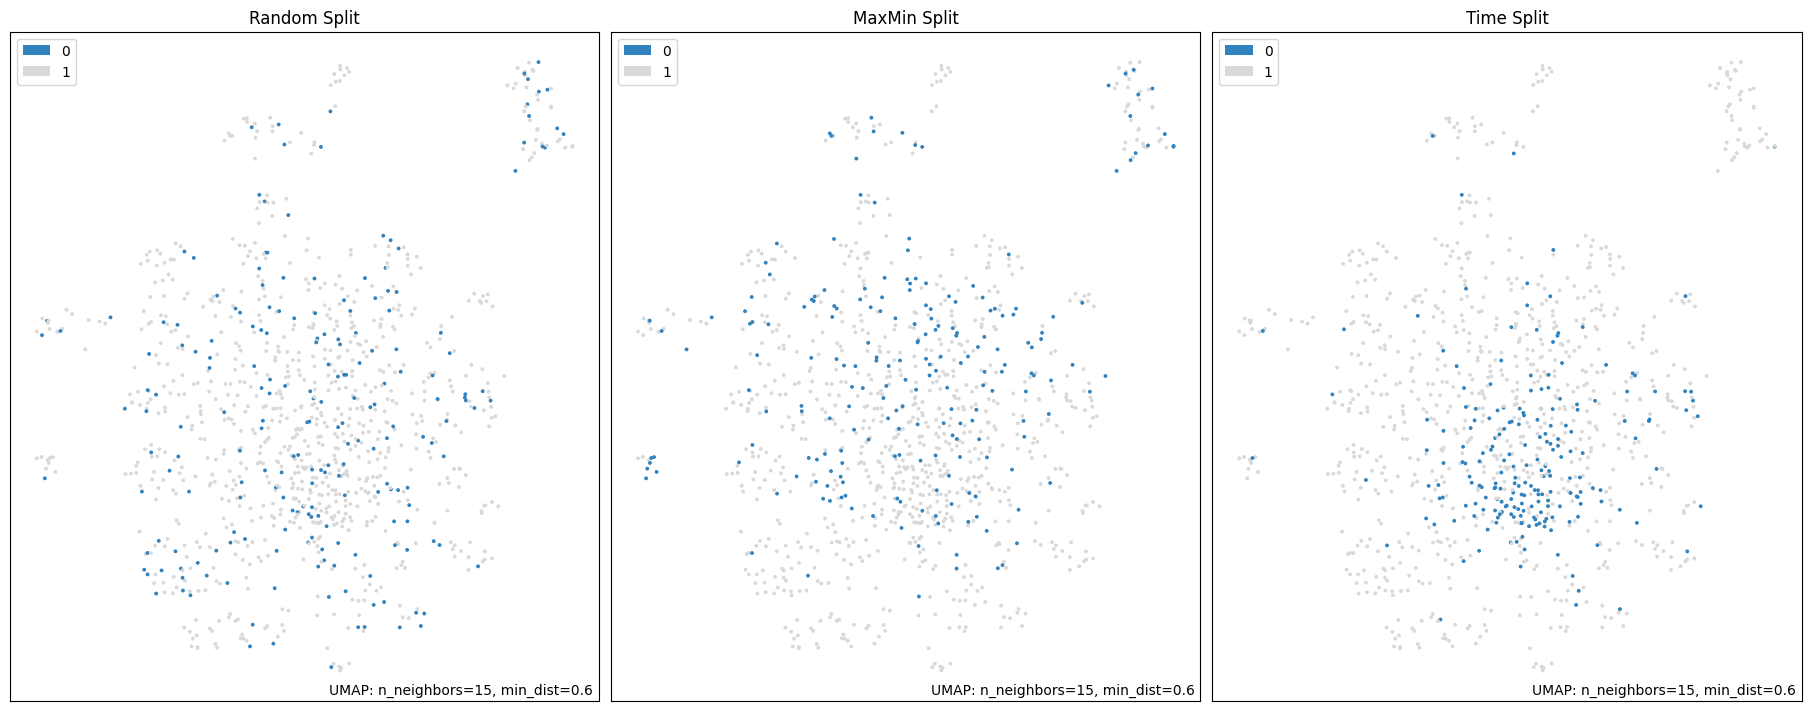

<Figure size 640x480 with 0 Axes>

In [24]:
# create a multiplot figure where points are labeled as 'test' or 'train' for each split.
fig, axes = plt.subplots(1, 3, figsize=(18, 7), layout='constrained') # plot matrices side-by-side
from matplotlib.lines import Line2D


umap.plot.points(mapper, labels=df[RANDOM_TARGET], ax=axes[0], theme='green')
axes[0].set_title("Random Split")
umap.plot.points(mapper, labels=df[MAX_TARGET], ax=axes[1], theme='green')
axes[1].set_title("MaxMin Split")
umap.plot.points(mapper, labels=df[TIME_TARGET], ax=axes[2], theme='green')
axes[2].set_title("Time Split")

plt.show()
plt.tight_layout()
plt.show();

/var/folders/z5/s_lphsr53bzfx0zyptx_j77c0000gn/T/ipykernel_93848/2997050431.py:16: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


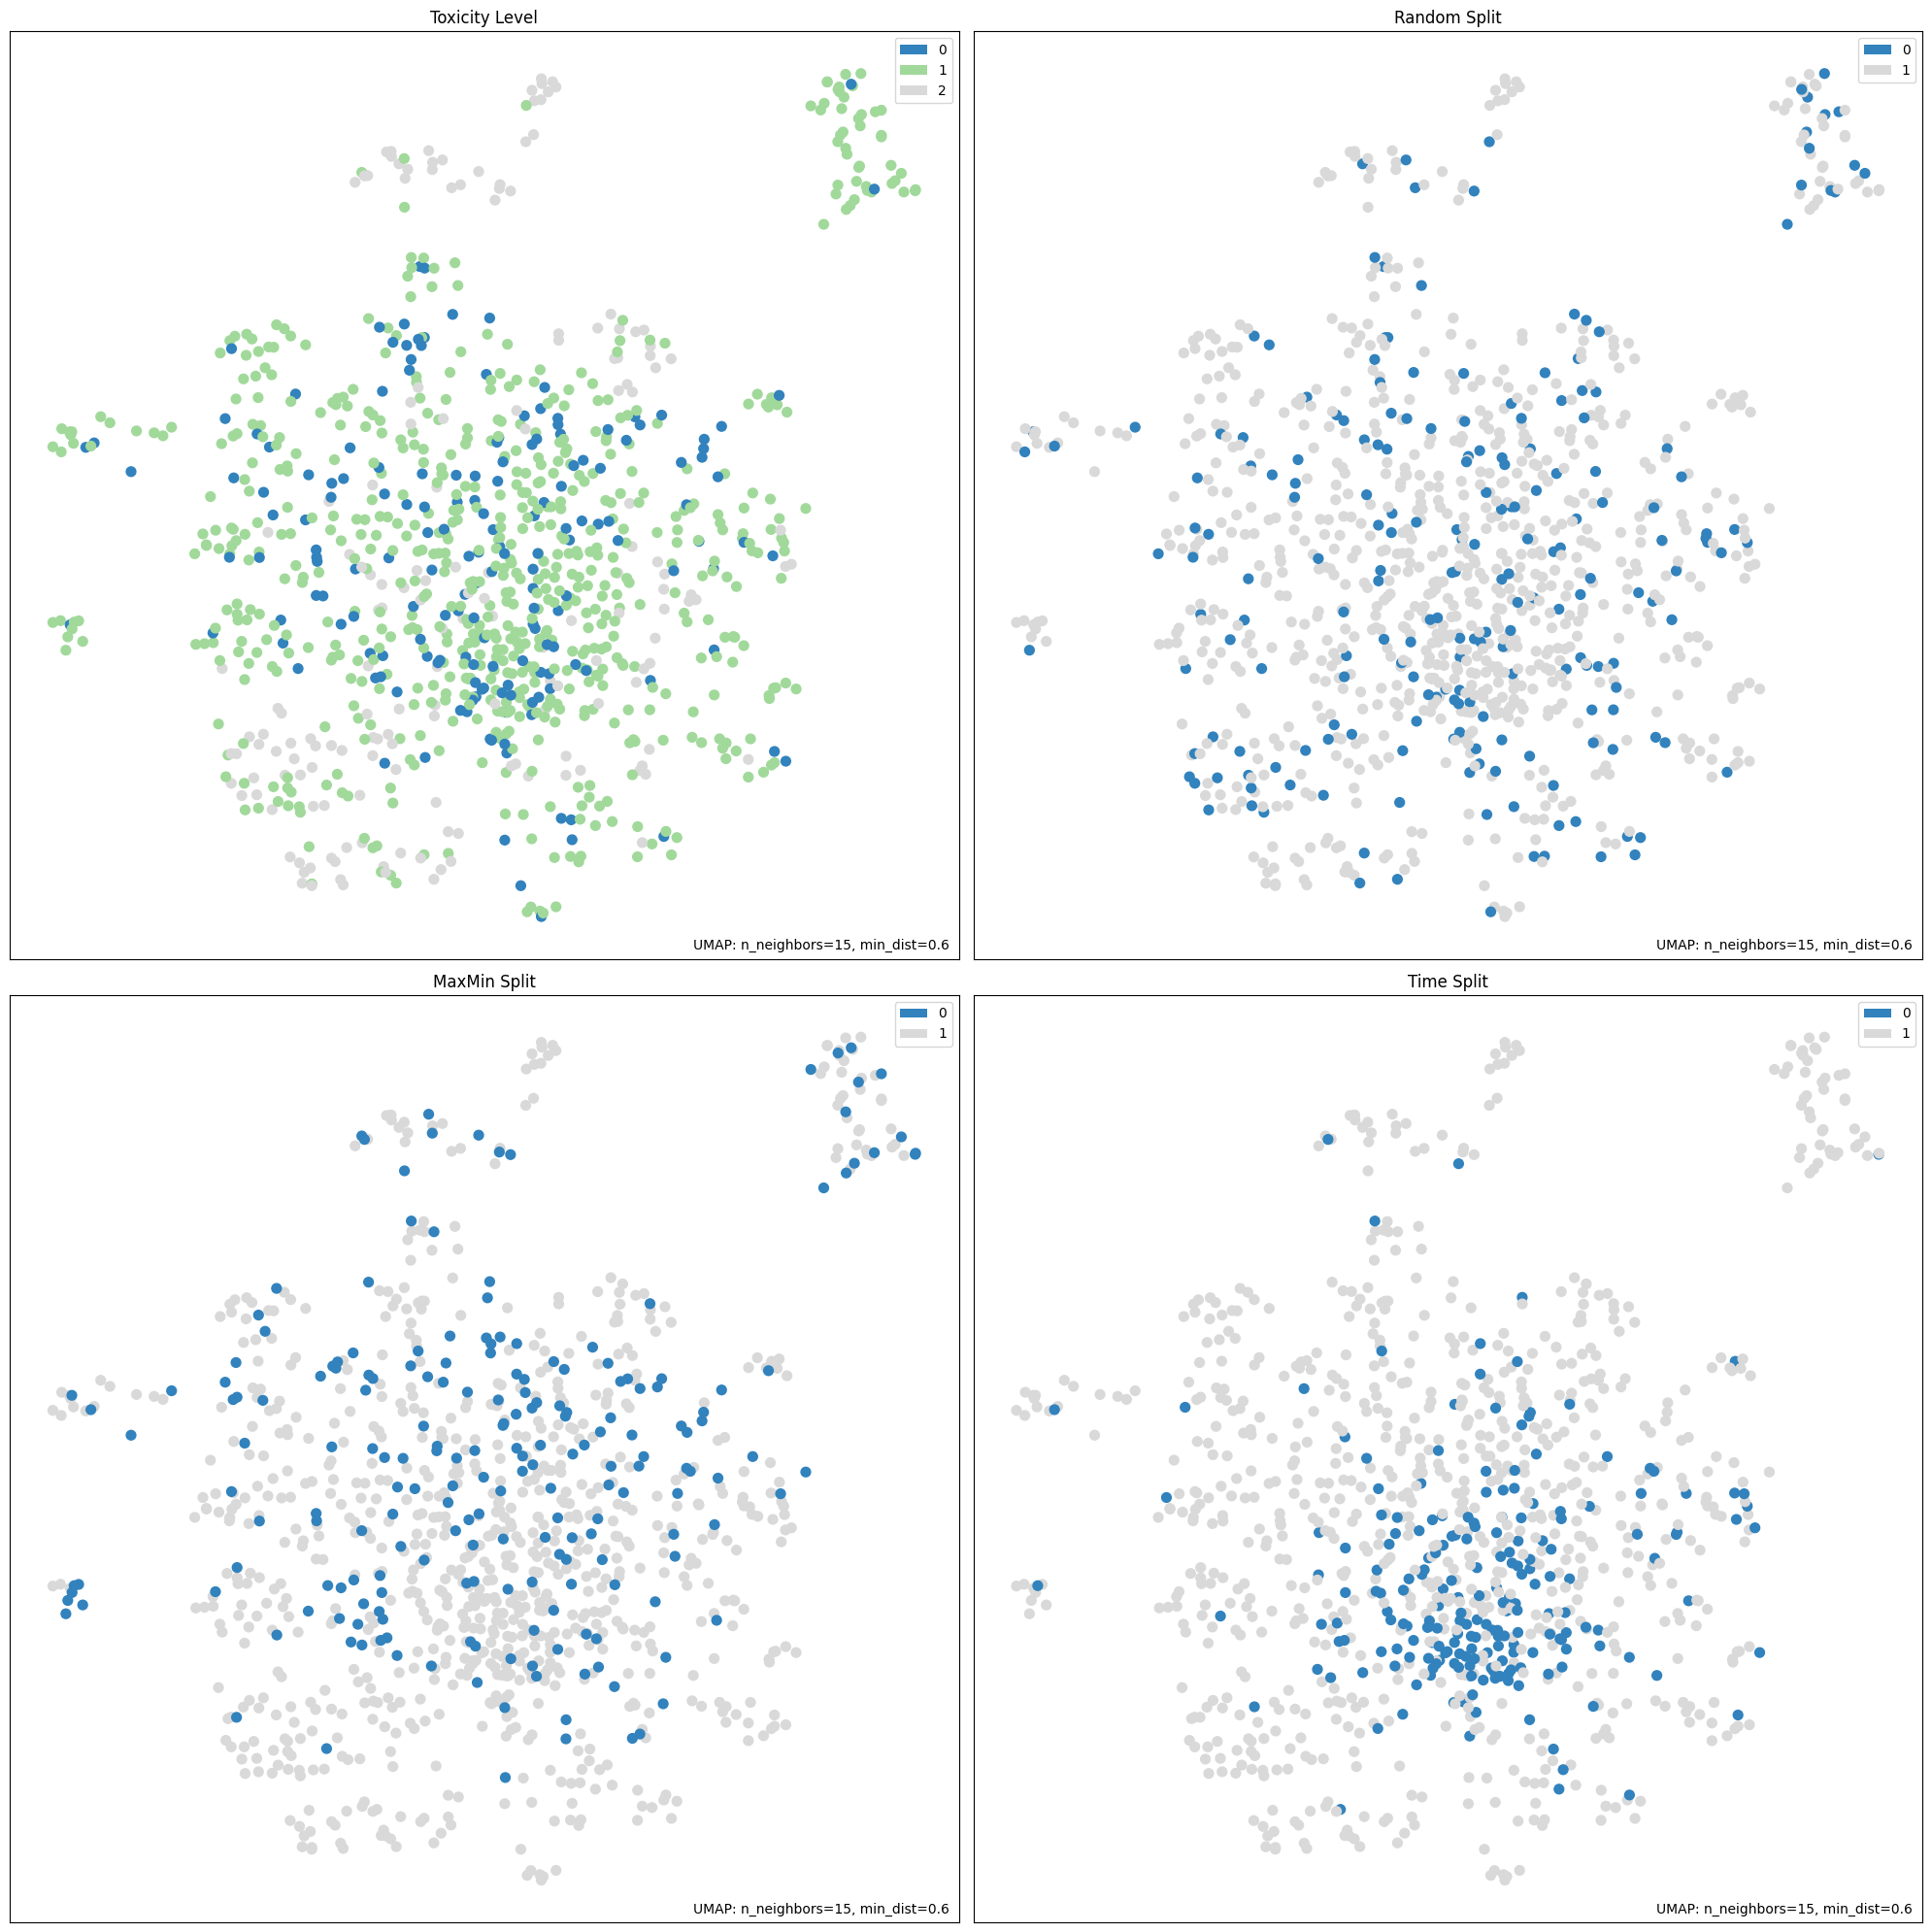

In [25]:
#create a multipanel figure which combines the two figures plotted above into one.
fig, axes = plt.subplots(2, 2, figsize=(20, 20), layout='constrained') # plot matrices side-by-side
from matplotlib.lines import Line2D

umap.plot.points(mapper, labels=df[TARGET], ax=axes[0,0], theme='green')
axes[0, 0].set_title("Toxicity Level")
umap.plot.points(mapper, labels=df[RANDOM_TARGET], ax=axes[0,1], theme='green')
axes[0, 1].set_title("Random Split")
umap.plot.points(mapper, labels=df[MAX_TARGET], ax=axes[1,0], theme='green')
axes[1, 0].set_title("MaxMin Split")
umap.plot.points(mapper, labels=df[TIME_TARGET], ax=axes[1,1], theme='green')
axes[1, 1].set_title("Time Split")

for ax in axes.flat:
    ax.collections[0].set_sizes([50])
plt.tight_layout()
plt.show();

/Users/ellasatterthwaite/Desktop/che1147/che1147-bees/.venv/lib/python3.10/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)


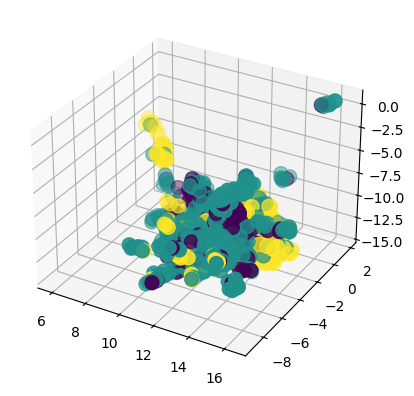

In [26]:
#fit a UMAP on three components for 3D visualization of full dataset and plot
data = df[FEATURES]
fit = umap.UMAP(
        n_neighbors=10,
        min_dist=0.7,
        n_components=3,
        metric='euclidean'
    )
u = fit.fit_transform(data);
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(u[:, 0], u[:, 1], u[:, 2], c=df[TARGET], cmap='viridis', s=100)
plt.title('', fontsize=18);